In [4]:
import sys
import yaml
import numpy as np
import pandas as pd
from pathlib import Path

sys.path.append("../..")
from src.solvers.ortools import solve_wflo_cpsat
from src.solvers.utils import save_benchmark_layout
from src.qubo_windfarm_layout.evaluation import load_layout_coordinates, layouts_folder_to_df
from src.qubo_windfarm_layout.visualization import plot_gurobi_refinement, plot_selected_layout
from src.qubo_windfarm_layout.model import build_local_candidates, get_warmstart, get_farm_area, build_local_wake_loss_matrix_optimized


# Strategies
Faccio una prima run grezza con risoluzione tale che ho invalid pairs non nulle e wake loss migliori della baseline.
Ho scelto GRID_RESOLUTION = 128m e TIMEOUT = 30m

Faccio run con GRID_RESOLUTION che va come potenza di due (64 -> 32 -> 16 -> 8) e raggio uguale a 2*GRID_RESOLUTION, TIMEOUT di 30m


In [5]:
# Variables
GRID_RESOLUTION = 256
TIMEOUT = 60 * 30
SOLVER = "ortools_cpsat"
STARTING_LAYOUT = f"../../results/layouts/{SOLVER}/cpsat_256_3600s.yaml"

# Parameters
RADIUS = 2*GRID_RESOLUTION
WAKE_LOSS_PATH = f"../../results/precomputed/{SOLVER}/wake_loss_{SOLVER}_res_{GRID_RESOLUTION}m_rad_{RADIUS}.npz"

(485, 2)
(1432, 2)


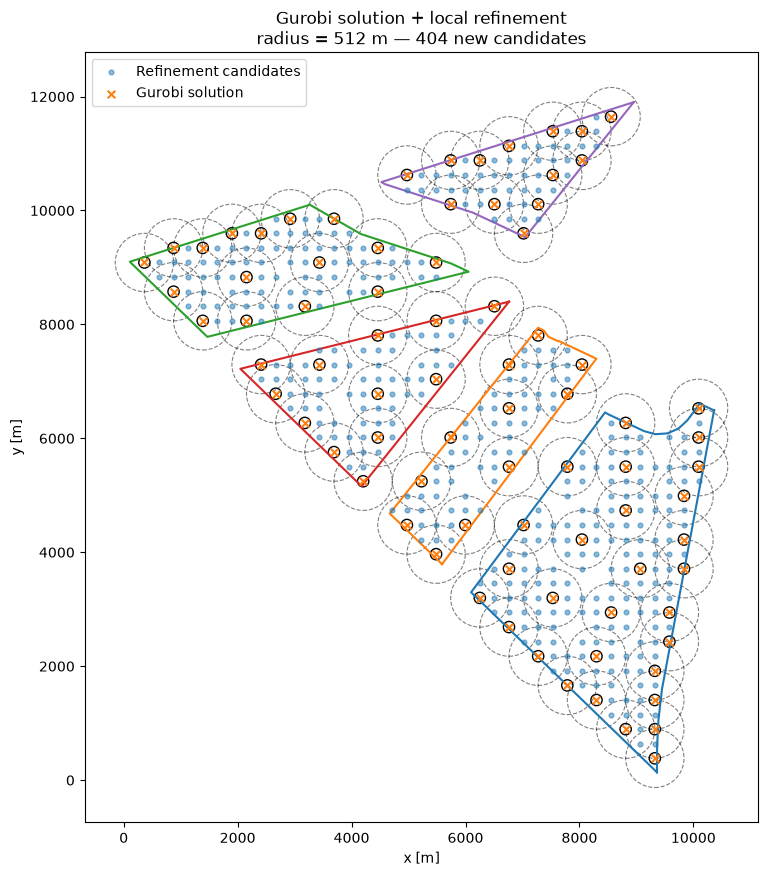

In [6]:
gurobi_positions = load_layout_coordinates(STARTING_LAYOUT)

_, farm_area = get_farm_area()

candidate_locations, invalid_pairs = build_local_candidates(
    gurobi_positions=gurobi_positions,
    farm_area=farm_area,
    radius_m=RADIUS,
    step_m=GRID_RESOLUTION,
)

print(candidate_locations.shape)
print(invalid_pairs.shape)

plot_gurobi_refinement(
    gurobi_positions=gurobi_positions,
    candidate_locations=candidate_locations,
    radius_m=RADIUS,
)

In [7]:
wake_loss_matrix, A0 = build_local_wake_loss_matrix_optimized(
    candidate_locations,
    output_path=WAKE_LOSS_PATH
)

wake_loss_matrix = np.load(WAKE_LOSS_PATH)["wake_loss_matrix"]

warm_start = get_warmstart(candidate_locations=candidate_locations, starting_layout=STARTING_LAYOUT)

Numero candidate locations: 485
Numero coppie totali: 117,370
Numero displacement unici: 2,199
Wake-loss data saved to: ../../results/precomputed/ortools_cpsat/wake_loss_ortools_cpsat_res_256m_rad_512.npz


In [13]:
result

(array([1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
        1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
        0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 

In [ ]:
result = solve_wflo_cpsat(
    wake_loss_matrix=wake_loss_matrix,
    invalid_pairs=invalid_pairs,
    n_turbines=81,
    warmstart=warm_start,
    time_limit_s=TIMEOUT,
)

array([  0,   3,   6,  12,  17,  29,  30,  33,  38,  46,  53,  64,  69,
        72,  75,  81,  90, 100, 110, 124, 127, 131, 132, 135, 147, 155,
       160, 169, 175, 179, 181, 190, 194, 197, 198, 209, 219, 230, 232,
       236, 242, 246, 249, 255, 261, 264, 272, 279, 293, 295, 304, 316,
       319, 320, 331, 332, 348, 354, 355, 357, 358, 361, 365, 394, 395,
       408, 411, 414, 426, 436, 438, 440, 442, 455, 457, 469, 471, 474,
       480, 482, 484])

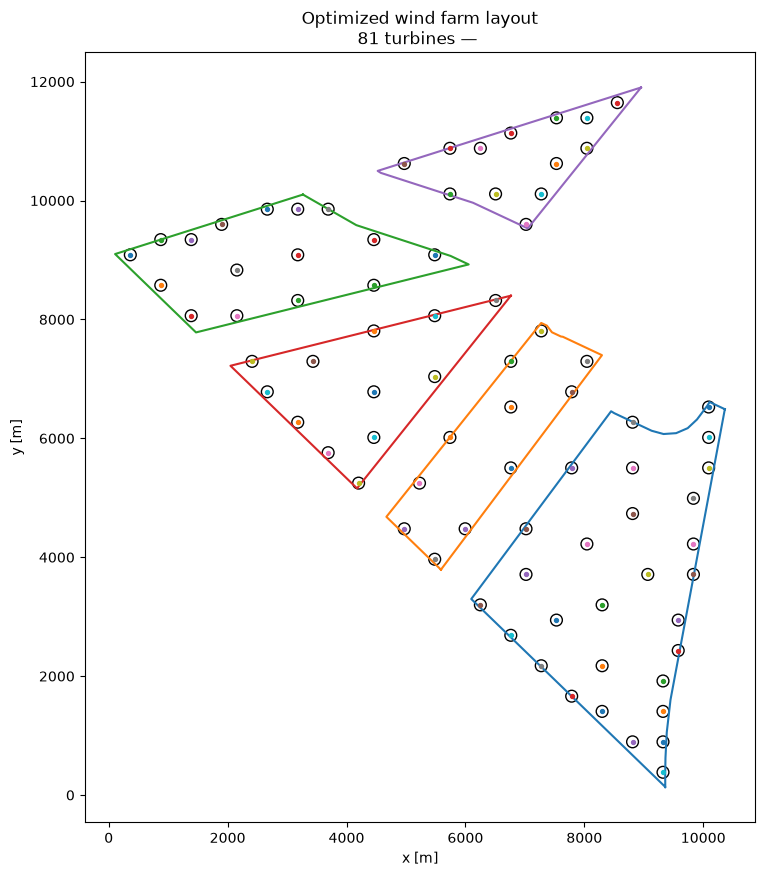

Layout saved to: /home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/pipelines/../../results/layouts/ortools_cpsat/ortools_cpsat_local_256m_1800s_warmstart.yaml
H_QUBO: 903237.3190486379
AEP: 2855.004908 GWh


PosixPath('/home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/pipelines/../../results/layouts/ortools_cpsat/ortools_cpsat_local_256m_1800s_warmstart.yaml')

In [23]:
selected_indices = np.flatnonzero(result[0])
selected_locations = candidate_locations[
    selected_indices
]

plot_selected_layout(selected_locations=selected_locations)

save_benchmark_layout(
    selected_locations=selected_locations,
    solver_name="ortools",
    output_dir=f"results/layouts/ortools_cpsat",
    filename=f"ortools_cpsat_local_{GRID_RESOLUTION}m_{TIMEOUT}s_warmstart.yaml",
    grid_resolution=GRID_RESOLUTION,
    time_limit_s=TIMEOUT,
    candidate_locations=candidate_locations,
    wake_loss_matrix=wake_loss_matrix,
)

In [24]:
df = layouts_folder_to_df(
    f"../../results/layouts/{SOLVER}"
)

df.sort_values(by="h_qubo", ascending=True)

,file,solver,grid_resolution,n_turbines,time_limit_s,h_qubo,aep_gwh
1,ortools_cpsat_local_256m_1800s_warmstart.yaml,ortools,256,81,1800,903237.319049,2855.004908
0,cpsat_256_3600s.yaml,cpsat,256,81,3600,NaN,2853.761924
